In [ ]:
import tensorflow as tf
from keras.models import Sequential
from keras.datasets import mnist
import matplotlib.pyplot as plt
import random
import numpy as np

2026-10-13 13:58:15.421390: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-13 13:58:15.472139: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-13 13:58:15.473464: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-13 13:58:17.913915: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train=x_train/255
x_test=x_test/255

In [15]:
import keras
from keras.models import Sequential

model = Sequential()

model.add(keras.layers.Flatten(input_shape=(28, 28)))
model.add(keras.layers.Dense(128, activation='relu'))
model.add(keras.layers.Dense(10, activation='softmax'))

In [10]:
model.compile(optimizer='sgd',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
H=model.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=5)


Epoch 1/5


2026-10-13 14:01:32.132962: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 188160000 exceeds 10% of free system memory.


1841/1875 [============================>.] - ETA: 0s - loss: 0.6581 - accuracy: 0.8308

2026-10-13 14:01:35.386180: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 31360000 exceeds 10% of free system memory.


1875/1875 [==============================] - 4s 2ms/step - loss: 0.6538 - accuracy: 0.8317 - val_loss: 0.3566 - val_accuracy: 0.9046
Epoch 2/5
1875/1875 [==============================] - 3s 2ms/step - loss: 0.3370 - accuracy: 0.9057 - val_loss: 0.2937 - val_accuracy: 0.9186
Epoch 3/5
1875/1875 [==============================] - 3s 2ms/step - loss: 0.2886 - accuracy: 0.9197 - val_loss: 0.2608 - val_accuracy: 0.9268
Epoch 4/5
1875/1875 [==============================] - 3s 2ms/step - loss: 0.2576 - accuracy: 0.9276 - val_loss: 0.2387 - val_accuracy: 0.9339
Epoch 5/5
1875/1875 [==============================] - 3s 2ms/step - loss: 0.2340 - accuracy: 0.9344 - val_loss: 0.2190 - val_accuracy: 0.9376


In [11]:
test_loss ,test_acc=model.evaluate(x_test,y_test)
print("Loss=%.3f" %test_loss)
print("Accuracy=%.3f" %test_acc)


 73/313 [=====>........................] - ETA: 0s - loss: 0.2924 - accuracy: 0.9170

2026-10-13 14:01:53.144722: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 31360000 exceeds 10% of free system memory.


313/313 [==============================] - 0s 1ms/step - loss: 0.2190 - accuracy: 0.9376
Loss=0.219
Accuracy=0.938


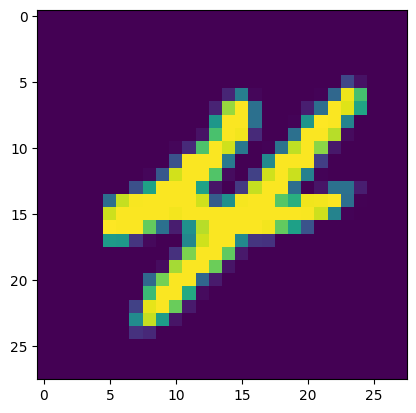

313/313 [==============================] - 0s 1ms/step
The handwritten number in image is 4


In [13]:
n=random.randint(0,9999)
plt.imshow(x_test[n])
plt.show()
prediction=model.predict(x_test)
print("The handwritten number in image is %d" %np.argmax(prediction[n]))

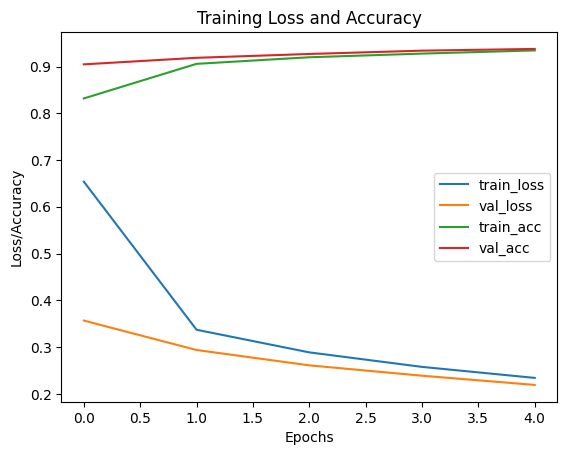

In [14]:
import matplotlib.pyplot as plt

plt.plot(H.history['loss'], label='train_loss')
plt.plot(H.history['val_loss'], label='val_loss')
plt.plot(H.history['accuracy'], label='train_acc')
plt.plot(H.history['val_accuracy'], label='val_acc')

plt.title('Training Loss and Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss/Accuracy')
plt.legend()

plt.show()